# CNN sur des chiffres 8×8 : des filtres aux erreurs

**Objectifs observables (90–120 min).** Lire les dimensions `(batch, channels, height, width)`, appliquer un filtre connu pour voir une feature map, calculer la sortie d'une convolution, entraîner un CNN et comparer à un modèle sur pixels avec un test tenu à part.

**Prérequis :** tensors PyTorch et boucle d'entraînement. Le dataset `digits` intégré à scikit-learn est petit, en niveaux de gris et adapté au CPU. Il ne mesure pas la qualité sur des photographies réelles.

## 1. Représenter des pixels comme un tensor

Les images de départ ont la forme `(n,8,8)` et des intensités de 0 à 16. `Conv2d` attend `(batch,channels,height,width)` : ajouter un canal donne `(n,1,8,8)`. Diviser par 16 place les pixels entre 0 et 1. La classe est un entier de 0 à 9. La séparation stratifiée conserve approximativement la proportion de chaque chiffre.

In [ ]:
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

torch.set_num_threads(1)
torch.manual_seed(10)
digits = load_digits()
X = torch.tensor(digits.images[:, None, :, :] / 16.0, dtype=torch.float32)
y = torch.tensor(digits.target, dtype=torch.long)
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=10)
train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=64, shuffle=True)
print('images:', tuple(X.shape), '| labels:', tuple(y.shape))
pixel_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
pixel_model.fit(x_train.numpy().reshape(len(x_train), -1), y_train.numpy())
pixel_accuracy = pixel_model.score(x_test.numpy().reshape(len(x_test), -1), y_test.numpy())
print('pixel logistic-regression baseline accuracy:', round(pixel_accuracy, 3))

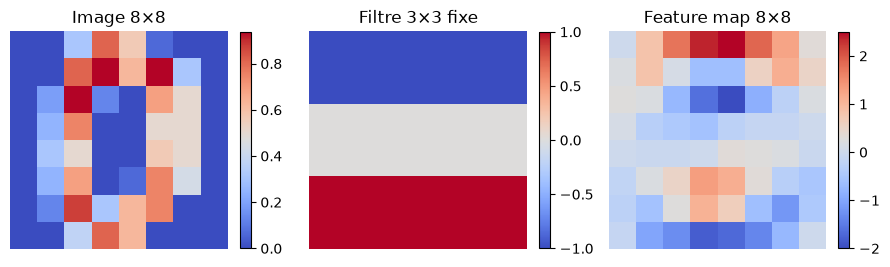

In [ ]:
import matplotlib.pyplot as plt
import torch.nn.functional as F

fixed_kernel = torch.tensor([[[[-1., -1., -1.], [0., 0., 0.], [1., 1., 1.]]]])
example_image = X[0:1]
feature_map = F.conv2d(example_image, fixed_kernel, padding=1)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, array, title in zip(axes, [example_image[0, 0], fixed_kernel[0, 0], feature_map[0, 0]],
                            ['Image 8×8', 'Filtre 3×3 fixe', 'Feature map 8×8']):
    image = ax.imshow(array.numpy(), cmap='coolwarm')
    ax.set_title(title); ax.axis('off')
    fig.colorbar(image, ax=ax, fraction=0.045)
plt.tight_layout(); plt.show()
print('Convolution output shape:', tuple(feature_map.shape))

## 2. Que calcule un filtre ?

Un filtre $K$ de forme `3×3` combine un voisinage local : $S_{i,j}=\sum_{u,v}K_{u,v}X_{i+u,j+v}$. PyTorch calcule une corrélation croisée (sans retourner `K`) ; l'usage pédagogique reste celui d'un filtre spatial. Avec `padding=1`, `stride=1`, la taille est $\lfloor(8+2-3)/1\rfloor+1=8$. Une couche à 8 filtres donnera `(batch,8,8,8)`.

Le filtre fixe ci-dessous accentue les transitions horizontales de l'intensité. Dans le CNN, les valeurs des filtres seront apprises. Le pooling 2×2 réduit une carte de `8×8` à `4×4`, puis une seconde fois à `2×2`.

In [ ]:
model = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(16 * 2 * 2, 10)
)
print('logits shape:', tuple(model(x_train[:5]).shape))

## 3. Entraîner, suivre la loss et évaluer

Les logits ont la forme `(batch,10)` : chaque colonne représente le score brut d'une classe. `CrossEntropyLoss` combine log-softmax et negative log-likelihood ; elle attend donc les **logits bruts** et des labels entiers. Après `zero_grad`, `backward` et `step`, la loss train est moyennée par nombre d'exemples. Le test reste hors de l'entraînement et du réglage.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()
train_losses = []
for epoch in range(6):
    model.train(); total_loss = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward(); optimizer.step()
        total_loss += loss.item() * len(labels)
    train_losses.append(total_loss / len(train_loader.dataset))
    print(f'epoch {epoch + 1}: mean train loss={train_losses[-1]:.3f}')
model.eval()
with torch.inference_mode():
    test_logits = model(x_test)
    test_prediction = test_logits.argmax(dim=1)
    test_accuracy = (test_prediction == y_test).float().mean().item()
print('held-out accuracy:', round(test_accuracy, 3))

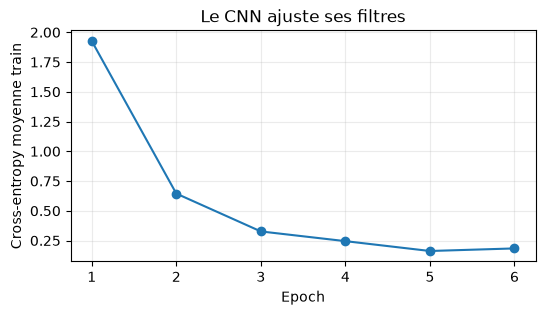

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, len(train_losses) + 1), train_losses, marker='o')
ax.set(xlabel='Epoch', ylabel='Cross-entropy moyenne train', title='Le CNN ajuste ses filtres')
ax.grid(alpha=0.25); plt.show()

## 4. Une moyenne cache les erreurs

La matrice de confusion indique quelles paires de chiffres sont confondues. La diagonale contient les bonnes classes ; une cellule hors diagonale `(vrai=i, prédit=j)` compte les erreurs `i→j`. Les exemples mal classés peuvent être ambigus même pour une personne. Ne déduisez pas une explication du CNN à partir de quelques images seulement.

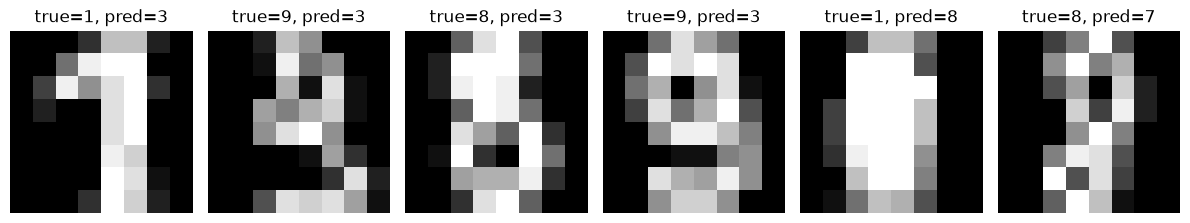

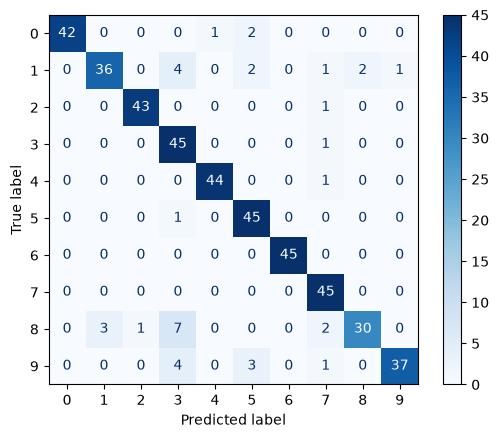

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

errors = torch.where(test_prediction != y_test)[0][:6]
fig, axes = plt.subplots(1, max(1, len(errors)), figsize=(12, 2.5))
for ax, index in zip(np.atleast_1d(axes), errors):
    ax.imshow(x_test[index, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'true={y_test[index].item()}, pred={test_prediction[index].item()}'); ax.axis('off')
plt.tight_layout(); plt.show()
ConfusionMatrixDisplay(confusion_matrix(y_test.numpy(), test_prediction.numpy())).plot(cmap='Blues')
plt.show()

## 5. Interprétation et limites

La régression logistique sur 64 pixels est une baseline forte pour ce petit jeu. Le CNN partage des filtres entre positions, ce qui donne un biais inductif spatial. Comparer leurs scores sur un seul split reste une démonstration : répéter plusieurs graines et isoler une validation avant de conclure à une amélioration.

Les images sont centrées, monochromes, faibles en résolution, et ne représentent pas des photos. Une augmentation mal choisie peut changer le label (une rotation de chiffre, par exemple). Transfer learning, Grad-CAM et segmentation demandent des protocoles distincts.

**Exercices.** Calculez les tailles spatiales pour `kernel=5,padding=0,stride=1`; dessinez les formes à chaque couche ; remplacez un seul filtre fixe et décrivez le changement de feature map ; comparez plusieurs graines de CNN sans toucher au test pour choisir les paramètres.